# Experiment 2 — Deconfliction layers with a fixed obstacle

This experiment evaluates the isolated application of strategic deconfliction and tactical deconfliction when the original UAV flight plan crosses a known fixed obstacle.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace, Cylinder3D, Obstacle
from musas.algorithms import (
    FirstOrderDynamics,
    DetourPathPlanner,
    MinimumSeparationConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
    MinimumSeparationTacticalConflictPrediction,
    FlightPlanAwareTracking,
    HybridGeometricManeuver
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    calculate_metrics,
    plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp2"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

The proposed flight plan is a straight line through the center of a cylindrical obstacle. The obstacle is known before the proposal is evaluated, so it can be handled strategically.

In [2]:
SIMULATION_END = 45.0
SAMPLING_INTERVAL = 0.25
LATERAL_CLEARANCE = 10.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0
NETWORK_DELAY = 0.1


flight_plan = FlightPlan([
        Waypoint(-100.0, 0.0, 100.0, 2.0),
        Waypoint(100.0, 0.0, 100.0, 32.0),
    ])

obstacle = Obstacle(
    obstacle_id="central-obstacle",
    name="Central obstacle",
    geometry=Cylinder3D(
        center_x=0.0,
        center_y=0.0,
        radius=20.0,
        minimum_z=90.0,
        maximum_z=110.0,
    ),
)
airspace = Airspace(obstacles={obstacle.obstacle_id: obstacle})

## Run the baseline and strategic-deconfliction cases

The baseline disables strategic deconfliction, causing the proposal to be approved unchanged. The SD case uses hybrid lateral/vertical path planning for the obstacle, followed by Recursive Time Shift FCFS if traffic conflicts remain.

In [3]:
CASES = {
    "sd_only": "With only strategic deconfliction",
    "td_only": "With only tactical deconfliction",
}

def run_case(case_name):
    dataset_path = DATASET_DIRECTORY / f"{case_name}.sqlite"
    strategic_conflict_prediction_algorithm = None
    strategic_deconfliction_algorithm = None
    tactical_conflict_prediction_algorithm = None
    tactical_deconfliction_algorithm = None
    tracking_algorithm = None

    if case_name == "sd_only":
        strategic_conflict_prediction_algorithm = MinimumSeparationConflictPrediction(
            minimum_separation_distance=20.0,
            sampling_interval=SAMPLING_INTERVAL,
        )
        path_planner = DetourPathPlanner(
            conflict_prediction_algorithm=strategic_conflict_prediction_algorithm,
            lateral_clearance=LATERAL_CLEARANCE,
            vertical_clearance=LATERAL_CLEARANCE,
            allow_vertical=False,
        )
        strategic_deconfliction_algorithm = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=strategic_conflict_prediction_algorithm,
            path_planner=path_planner,
        )


    elif case_name == "td_only":
        tactical_conflict_prediction_algorithm = MinimumSeparationTacticalConflictPrediction(
                    minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
                    maximum_time_difference=0.25,
                )

        tactical_deconfliction_algorithm = HybridGeometricManeuver(
            conflict_prediction_algorithm=tactical_conflict_prediction_algorithm,
            airspace_clearance=LATERAL_CLEARANCE,
            maximum_speed=15.0,
            )
        tracking_algorithm = FlightPlanAwareTracking()


    simulation = Simulation(
        airspace=airspace,
        network_delay=NETWORK_DELAY,
        flight_update_interval=0.1,
        trajectory_record_interval=0.2,
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "deconfliction_with_obstacle",
            "case": case_name,
        },
        overwrite_dataset=True,
        strategic_conflict_prediction_algorithm=strategic_conflict_prediction_algorithm,
        strategic_deconfliction_algorithm=strategic_deconfliction_algorithm,
        tactical_conflict_prediction_algorithm=tactical_conflict_prediction_algorithm,
        tactical_deconfliction_algorithm=tactical_deconfliction_algorithm,
        tracking_algorithm=tracking_algorithm,
        history_window=6,
        prediction_horizon=10,
        prediction_step=0.5,
        tactical_assessment_interval=0.1,
    )

    simulation.add_uav(
        name="UAV 1",
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=100.0,
            velocity_time_constant=0.0,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=15.0,
        ),
        waypoint_acceptance_radius=1.0,
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {case_name: run_case(case_name) for case_name in CASES}
dataset_paths

{'sd_only': PosixPath('outputs/output_exp2/datasets/sd_only.sqlite'),
 'td_only': PosixPath('outputs/output_exp2/datasets/td_only.sqlite')}

## Metrics

The relevant outputs are the detected strategic conflicts, modified flights, obstacle violations, and the planned and executed distances and times.

In [4]:
print(
    f"{'Case':<38} {'conflicts':>10} {'modified':>10} "
    f"{'violations':>11} {'plan dist.':>12} {'real dist.':>12} "
    f"{'plan time':>11} {'real time':>10}"
)
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=20.0,
            collision_distance=5.0,
        )
    values = metrics["per_uav"]["UAV 1"]
    real_distance = values["actual_distance"]
    real_distance_text = (
        "not completed" if real_distance is None else f"{real_distance:.2f}"
    )
    real_time = values["actual_time"]
    real_time_text = "not completed" if real_time is None else f"{real_time:.1f}"
    print(
        f"{CASES[case_name]:<38} "
        f"{metrics['detected_strategic_conflicts']:10d} "
        f"{metrics['modified_flights']:10d} "
        f"{metrics['obstacle_violations']:11d} "
        f"{values['planned_distance']:12.2f} "
        f"{real_distance_text:>12} "
        f"{values['planned_time']:11.1f} "
        f"{real_time_text:>10}"
    )

Case                                    conflicts   modified  violations   plan dist.   real dist.   plan time  real time
With only strategic deconfliction               1          1           0       200.00       209.84        30.0       31.7
With only tactical deconfliction                0          1           0       200.00       225.69        30.0       29.9


## Authorized flight plans

The stored plan versions make the strategic counterproposal explicit.

In [5]:
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        versions = dataset.get_flight_plan_versions("UAV 1")
        plan = dataset.get_flight_plan(
            "UAV 1",
            "authorized",
            versions[-1],
        )
    print(f"\n{CASES[case_name]}:")
    for waypoint in plan.waypoint_list:
        print(
            f"  ({waypoint.x:7.2f}, {waypoint.y:7.2f}, "
            f"{waypoint.z:6.2f}) at t={waypoint.t:6.2f} s"
        )


With only strategic deconfliction:
  (-100.00,    0.00, 100.00) at t=  2.00 s
  ( -30.00,  -30.00, 100.00) at t= 13.42 s
  (  30.00,  -30.00, 100.00) at t= 22.42 s
  ( 100.00,    0.00, 100.00) at t= 33.85 s

With only tactical deconfliction:
  ( -52.00,    0.00, 100.00) at t=  9.10 s
  ( -30.10,  -30.10, 100.00) at t= 14.10 s
  (  30.10,  -30.10, 100.00) at t= 18.11 s
  (  60.76,    0.00, 100.00) at t= 26.11 s
  ( 100.00,    0.00, 100.00) at t= 32.00 s


## Flight-plan and trajectory figures

These figures are generated directly from each SQLite dataset with `plot_dataset()`.

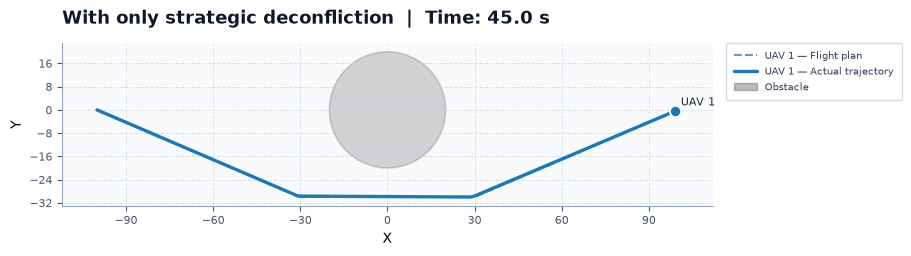

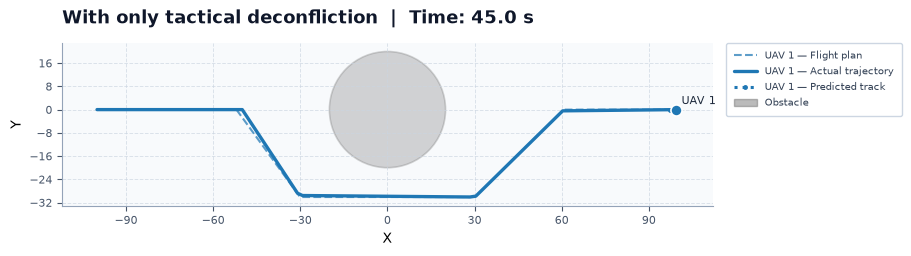

In [6]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=True,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=True,
        frame_step=0.5,
        figure_size=(9.0, 6.0),
        title=CASES[case_name],
    )

for case_name, dataset_path in dataset_paths.items():
    figure_path = OUTPUT_DIRECTORY / f"{case_name}.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        timestamp=SIMULATION_END,
        output_path=figure_path,
    )

## Animations

These animations are generated with `animate_dataset()`.

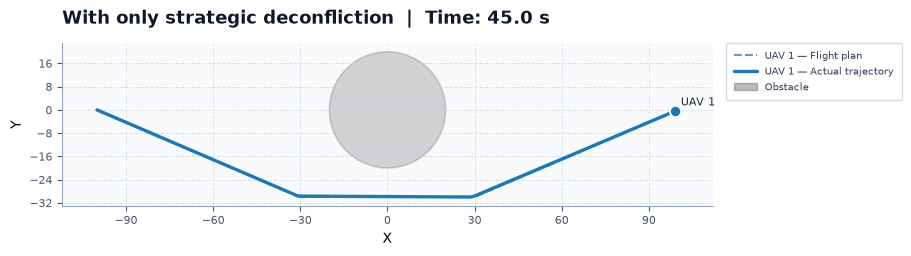

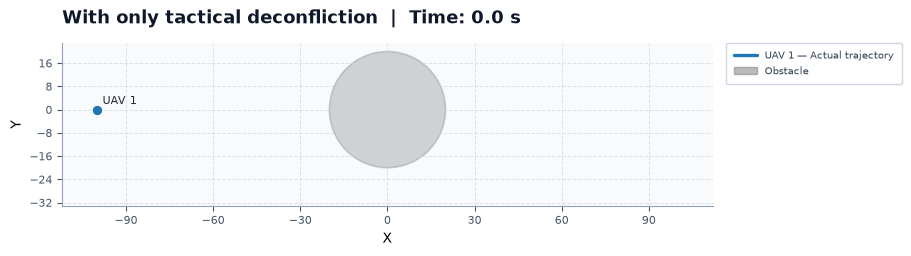

In [7]:
for case_name, dataset_path in dataset_paths.items():
    animation_path = OUTPUT_DIRECTORY / f"{case_name}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        output_path=animation_path,
        fps=6.0,
        dpi=100,
    )


## Expected interpretation

Without strategic deconfliction, the original straight plan is approved and the UAV enters the obstacle. With strategic deconfliction, the conflict predictor detects the obstacle before departure and the deconfliction algorithm issues a longer lateral counterproposal that avoids the prohibited volume.